# Projeto Aplicado III - SISTEMA DE RECOMENDAÇÃO DE LIVROS NA PLATAFORMA SKOOB

 ### --- 1. Definição de Bibliotecas Python ---


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import kagglehub
import os
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel


### --- 2. Carregando os dados ---

[texto do link](https://)Será utilizada a base de dados "Livros Skoob", disponível em https://www.kaggle.com/datasets/victorstein/livros-skoob

In [ ]:
path = kagglehub.dataset_download("victorstein/livros-skoob")

print("Path to dataset files:", path)

100%|██████████| 4.76M/4.76M [00:00<00:00, 85.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/victorstein/livros-skoob/versions/1


In [ ]:
for arquivo in os.listdir(path):
    print(arquivo)

dados.csv


In [ ]:
livros = pd.read_csv(os.path.join(path, "dados.csv"))
livros.head()

,titulo,autor,ISBN_13,ISBN_10,ano,paginas,idioma,editora,rating,avaliacao,resenha,abandonos,relendo,querem_ler,lendo,leram,descricao,genero,male,female
0,Orçamento sem falhas,Nath Finanças,9.786556e+12,6555601566,2021,128,português,Intrínseca,0.0,0,0,0,0,1,0,0,"Quando o assunto é dinheiro, não dá para achar...","Economia, Finanças / Literatura Brasileira / N...",28,72
1,Minha Sombria Vanessa,Kate Elizabeth Russell,9.788551e+12,8551006274,2020,432,português,Intrínseca,4.3,2,653,48,3,6,389,2,Elogiado por Gillian Flynn e considerado um do...,Drama / Ficção / Literatura Estrangeira / Susp...,7,93
2,Recursão,Blake Crouch,9.788551e+12,8551005375,2020,320,português,Intrínseca,4.4,2,618,22,2,6,295,2,E se um dia memórias vívidas de coisas que nun...,Ficção / Ficção científica / Literatura Estran...,21,79
3,"M, o Filho do Século",Antonio Scurati,9.788551e+12,855100607X,2020,816,português,Intrínseca,4.6,60,12,1,0,951,49,55,"O romance M, o Filho do Século conta em trama ...","Biografia, Autobiografia, Memórias / História ...",37,63
4,Oblivion Song: Entre Dois Mundos,Robert Kirkman,9.788551e+12,8551006258,2020,136,português,Intrínseca,4.1,166,16,0,0,376,6,184,Mestre em traçar universos distópicos permeado...,"Ficção / HQ, comics, mangá / Literatura Estran...",44,56


## --- 3. Análise Exploratória de Dados ---

In [ ]:
livros.info()
livros.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11975 entries, 0 to 11974
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   titulo      11975 non-null  object 
 1   autor       11971 non-null  object 
 2   ISBN_13     11216 non-null  float64
 3   ISBN_10     11216 non-null  object 
 4   ano         11975 non-null  int64  
 5   paginas     11975 non-null  int64  
 6   idioma      11973 non-null  object 
 7   editora     11974 non-null  object 
 8   rating      11975 non-null  float64
 9   avaliacao   11975 non-null  int64  
 10  resenha     11975 non-null  int64  
 11  abandonos   11975 non-null  int64  
 12  relendo     11975 non-null  int64  
 13  querem_ler  11975 non-null  int64  
 14  lendo       11975 non-null  int64  
 15  leram       11975 non-null  int64  
 16  descricao   11318 non-null  object 
 17  genero      11386 non-null  object 
 18  male        11975 non-null  int64  
 19  female      11975 non-nul

,titulo,autor,ISBN_13,ISBN_10,ano,paginas,idioma,editora,rating,avaliacao,resenha,abandonos,relendo,querem_ler,lendo,leram,descricao,genero,male,female
0,Orçamento sem falhas,Nath Finanças,9.786556e+12,6555601566,2021,128,português,Intrínseca,0.0,0,0,0,0,1,0,0,"Quando o assunto é dinheiro, não dá para achar...","Economia, Finanças / Literatura Brasileira / N...",28,72
1,Minha Sombria Vanessa,Kate Elizabeth Russell,9.788551e+12,8551006274,2020,432,português,Intrínseca,4.3,2,653,48,3,6,389,2,Elogiado por Gillian Flynn e considerado um do...,Drama / Ficção / Literatura Estrangeira / Susp...,7,93
2,Recursão,Blake Crouch,9.788551e+12,8551005375,2020,320,português,Intrínseca,4.4,2,618,22,2,6,295,2,E se um dia memórias vívidas de coisas que nun...,Ficção / Ficção científica / Literatura Estran...,21,79
3,"M, o Filho do Século",Antonio Scurati,9.788551e+12,855100607X,2020,816,português,Intrínseca,4.6,60,12,1,0,951,49,55,"O romance M, o Filho do Século conta em trama ...","Biografia, Autobiografia, Memórias / História ...",37,63
4,Oblivion Song: Entre Dois Mundos,Robert Kirkman,9.788551e+12,8551006258,2020,136,português,Intrínseca,4.1,166,16,0,0,376,6,184,Mestre em traçar universos distópicos permeado...,"Ficção / HQ, comics, mangá / Literatura Estran...",44,56


#### Contagem de dados na base de dados

Base de dados tem 11975 Livros

#### Distribuição das notas:

rating
0.0      400
1.0        7
1.3        3
1.5        4
1.7        1
1.8        3
2.0       27
2.1        4
2.2        7
2.3       16
2.4        6
2.5       31
2.6       18
2.7       34
2.8       63
2.9       66
3.0      248
3.1      165
3.2      175
3.3      348
3.4      398
3.5      582
3.6      641
3.7      708
3.8      985
3.9      913
4.0     1231
4.1     1060
4.2     1023
4.3      979
4.4      631
4.5      469
4.6      264
4.7      136
4.8       86
4.9       12
5.0      220
5.3        1
5.5        1
5.8        1
6.0        5
6.5        1
7.0        1
10.0       1
Name: count, dtype: int64


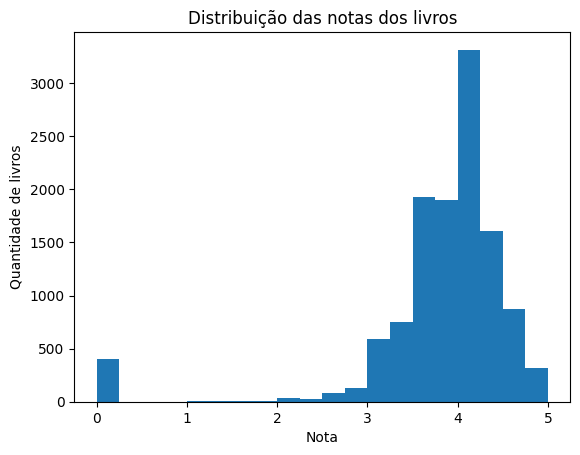

In [ ]:
print(livros["rating"].value_counts().sort_index())

plt.hist(livros["rating"].dropna(), bins=20, range=(0, 5))

plt.xlabel("Nota")
plt.ylabel("Quantidade de livros")
plt.title("Distribuição das notas dos livros")

plt.show()

Verificamos que existem 11 notas que estão fora do intervalo, pois possuem valor maior que 5, que é o valor máximo da escala.
Verficamos que existem 400 notas 0, que podem indicar ausência de nota.
Verifica-se que a maior parte das notas está em torno da nota 4.

#### Quantidade de avaliações:

avaliacao
0       400
1      1014
2       606
3       511
4       387
       ... 
993       1
994       2
996       1
998       3
999       2
Name: count, Length: 859, dtype: int64


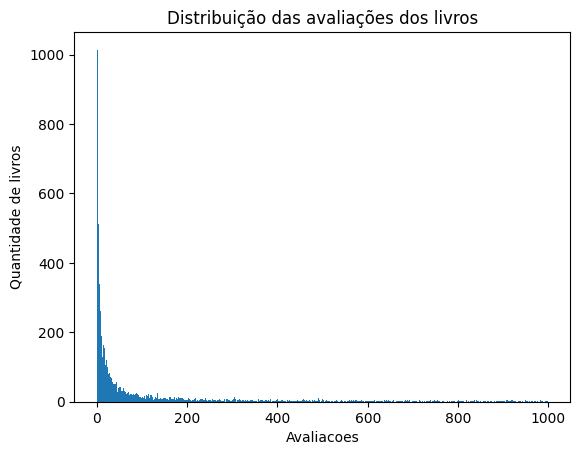

In [ ]:
print(livros["avaliacao"].value_counts().sort_index())
plt.hist(livros["avaliacao"].dropna(), bins=1000)
plt.xlabel("Avaliacoes")
plt.ylabel("Quantidade de livros")
plt.title("Distribuição das avaliações dos livros")
plt.show()

In [ ]:
livros["avaliacao"].describe()

,avaliacao
count,11975.000000
mean,114.259457
std,200.385036
min,0.000000
25%,5.000000
50%,22.000000
75%,114.000000
max,999.000000


O número de livros que não receberam avaliações também é de 400 livros, o que aumenta a suspeita de que as notas 0 são de livros que não receberam avaliações.


## --- 4. Testando um modelo TF-IDF---

###Preparando os dados para o modelo

O modelo usará o campo "genero" e "descricao" para comparar sinopses e generos entre livros indicados pelo usuário e a base de dados para gerar recomendações similares.
Para verificar a viabilidade dessa estratégia, verificaremos a qualidade dos dados desses campos.

#### Contagem de livros por gênero

In [ ]:
print("Gêneros preenchidos:", livros["genero"].notna().sum())
print("Gêneros ausentes:", livros["genero"].isna().sum())

Gêneros preenchidos: 11386
Gêneros ausentes: 589


In [ ]:
generos = livros["genero"].dropna().str.split("/").explode()
generos = generos.str.strip()
generos = generos[generos.ne("")]
contagem_generos = generos.value_counts()
print(contagem_generos.head(50))
print("Quantidade de gêneros distintos:", generos.nunique())

genero
Literatura Estrangeira                4011
Ficção                                2679
Romance                               2309
Literatura Brasileira                  903
Fantasia                               807
Suspense e Mistério                    678
Jovem adulto                           678
Infantojuvenil                         650
Não-ficção                             529
Autoajuda                              439
Aventura                               361
Biografia, Autobiografia, Memórias     352
Religião e Espiritualidade             296
Romance policial                       271
Drama                                  267
História                               241
Ficção científica                      238
Contos                                 172
Crime                                  171
Erótico                                159
Negócios e Empreendedorismo            145
Psicologia                             136
Terror                                 133
Infa

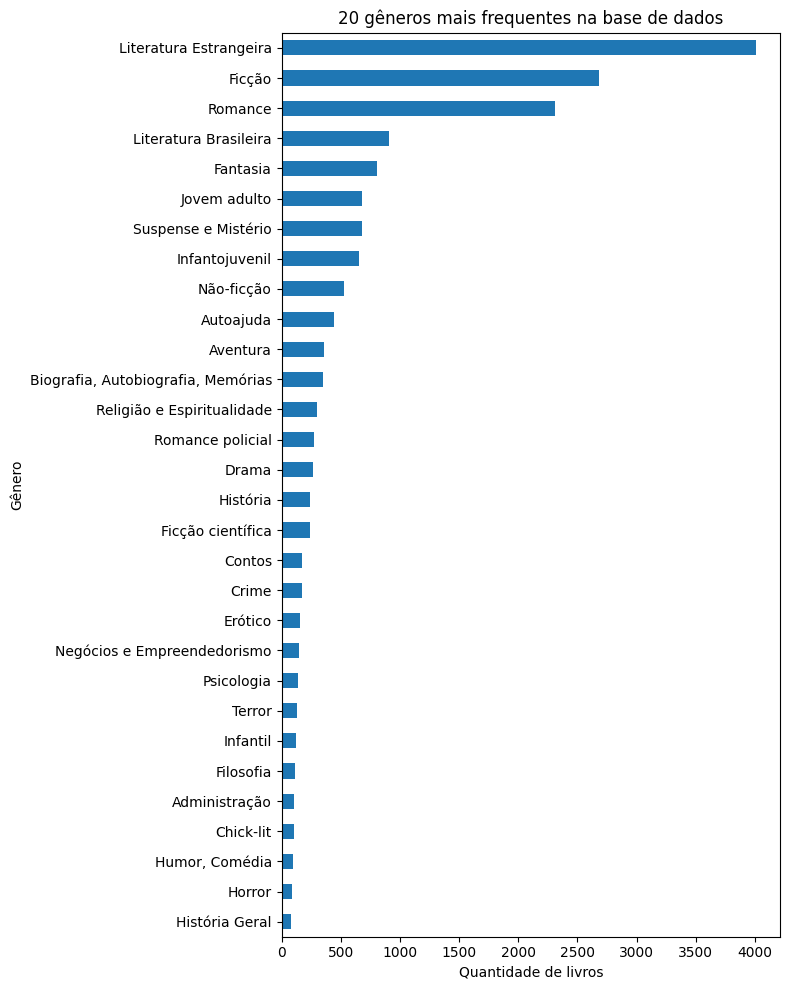

In [ ]:
plt.figure(figsize=(8, 10))
contagem_generos.head(30).sort_values().plot(kind="barh")
plt.xlabel("Quantidade de livros")
plt.ylabel("Gênero")
plt.title("20 gêneros mais frequentes na base de dados")

plt.tight_layout()
plt.show()

####Verificação do campo "descricao"

#####Contagem de campos vazios

In [ ]:
print("Total de livros:", len(livros))
print("Descrições preenchidas:", livros["descricao"].notna().sum())
print("Descrições ausentes:", livros["descricao"].isna().sum())

print(
    "Percentual ausente:",
    round(livros["descricao"].isna().mean() * 100, 2),
    "%"
)

Total de livros: 11975
Descrições preenchidas: 11318
Descrições ausentes: 657
Percentual ausente: 5.49 %


#####Análise do tamanho das sinopses

In [ ]:
descricao = livros["descricao"].fillna("").astype(str).str.strip()

livros["tamanho_descricao"] = descricao.str.len()
livros["quantidade_palavras"] = descricao.str.split().str.len()

print(livros[["tamanho_descricao", "quantidade_palavras"]].describe())

       tamanho_descricao  quantidade_palavras
count       11975.000000         11975.000000
mean          901.616117           150.522923
std           604.172642           100.184094
min             0.000000             0.000000
25%           518.000000            87.000000
50%           810.000000           136.000000
75%          1171.000000           196.000000
max          5990.000000           944.000000


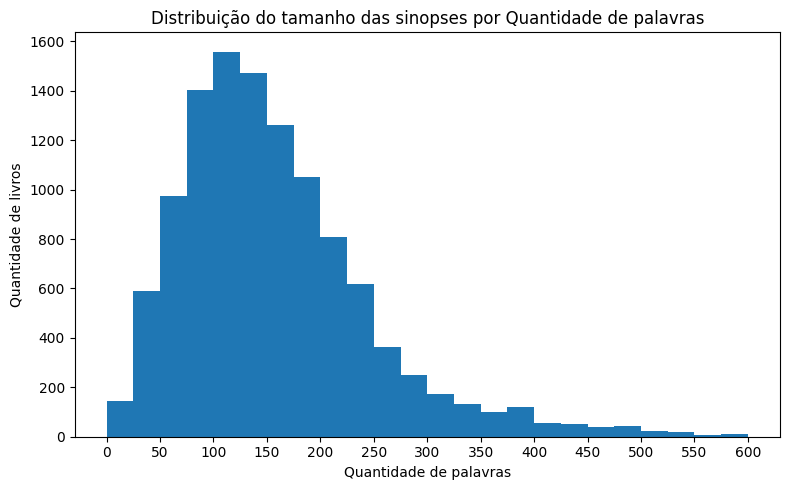

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    livros.loc[descricao.ne(""), "quantidade_palavras"],
    bins=24,
    range=(0, 600)
)
plt.xticks(np.arange(0, 601, 50))
plt.xlabel("Quantidade de palavras")
plt.ylabel("Quantidade de livros")
plt.title("Distribuição do tamanho das sinopses por Quantidade de palavras")

plt.tight_layout()
plt.show()

In [ ]:
with pd.option_context("display.max_colwidth", None):
    display(
        livros.loc[
            descricao.ne(""),
            ["titulo", "descricao", "genero", "quantidade_palavras"]
        ].sample(5, random_state=8)
    )

,titulo,descricao,genero,quantidade_palavras
11561,Star Wars: A Resistência Renasce,"Batalhas serão travadas, alianças serão forjadas e a Resistência renascerá Nesta história que se passa entre os filmes Star Wars: Os Últimos Jedi, de 2017, e o aguardado Star Wars: A Ascensão Skywalker, acompanharemos a General Leia Organa, Poe Dameron, Rey e Finn lutarem em prol da reconstrução da Resistência após sua grande perda nas mãos da Primeira Ordem Das selvas de Ryloth até os estaleiros de Corellia, a sombra da Primeira Ordem é grande e aqueles com coragem para combater a escuridão estão espalhados e isolados Se a esperança é sobreviver, a Resistência deve viajar por toda a Galáxia em busca de mais líderes  incluindo aqueles que, em tempos passados, ajudaram uma rebelião nascente a derrubar um império",Fantasia / Ficção científica / Literatura Estrangeira,120
7767,O Tatuador de Auschwitz,"A incrível história, baseada em fatos, de um amor que os cruéis muros de Auschwitz não foramcapazes de impedirNesse romance histórico, um testemunho da coragem daqueles que ousaram enfrentar o sistema da Alemanha nazista,o leitor será conduzido pelos horrores vividos dentro dos campos de concentração da Alemanha nazista e verá que oamor não pode ser limitado por muros e cercasLale Sokolov e Gita Fuhrmannova, dois judeus eslovacos, se conheceram em um dos mais terríveis lugares que ahumanidade já viu: o campo de concentração e extermínio de Auschwitz, durante a Segunda Guerra Mundial Nocampo, Lale foi incumbido de tatuar os números de série dos prisioneiros que chegavam, trazidos pelos nazistas literalmente marcando na pele das vítimas o que se tornaria um grande símbolo do Holocausto Ainda que fosseacusado de compactuar com os carcereiros, Lale, no entanto, aproveitava sua posição privilegiada para ajudar outrosprisioneiros, trocando joias e dinheiro por comida para mantê-los vivos e designando funções administrativas parapoupar seus companheiros do trabalho braçal do campoNesse ambiente, feito para destruir tudo o que nele tocasse, Lale e Gita viveram um amor proibido, permitindo-se vivermesmo sabendo que a morte era iminente",Ficção / Literatura Estrangeira / Romance,187
602,Linhagem zero,"Uma nova saga tem início Em Linhagem Zero: Despertar, um grupo de jovens está determinado a impedir a qualquer custo que o Endgame aconteça Eles se autonomeiam Linhagem Zero Década de 1970 Mike Stavros acabou de entrar para a faculdade e acredita que esta é uma oportunidade para tornar-se independente e ter controle sobre sua vida Assim que faz novos amigos, ele logo percebe que nada vai sair como esperado Mike se envolve perigosamente com essas pessoas e toma conhecimento do que é o Endgame e qual é o objetivo dos Jogadores responsáveis pelo destino da humanidade De uma hora para outra, Mike passa a fazer parte da Linhagem Zero, que está determinada a caçar a geração de Jogadores que precede a dos 12 envolvidos em o Chamado Mike e seus novos amigos estão reunidos em torno de uma importante missão: matar todos os Jogadores que tem a intenção de competir no Endgame O Endgame ainda não começou, e a Linhagem Zero vai fazer de tudo para o Jogo não acontecer",,171
168,Rede de Sussurros,"Grace, Sloane e Ardie são amigas e trabalham há anos nos escritórios de uma das marcas esportivas mais famosas do mundo As três ocupam cargos de importância do setor jurídico da companhia No entanto, quando morre o CEO da empresa, o trio recebe a notícia com uma angustia ainda maior do que o esperado: Ames Garrett, o chefe direto delas, um executivo de postura reprovável em seu trato com as mulheres, é o favorito para herdar o cargoA ascensão de Ames  um homem com histórico de intimidação, chantagem e assédio moral e sexual  oferece perigo real para suas subordinadas do escritório Elas sabem como as engrenagens do machismo funcionam na sociedade: não são raras as vezes em que a mulher é compelida a manter o silêncio para evitar represálias  a aceitar as regras do jogo em vez de a

#####TF-IDF

Criando uma cópia da base de dados considerando apenas os livros que possuem campo de descricao não-nulo

In [ ]:
livros_tfidf = livros.copy()
livros_tfidf["descricao"] = (
    livros_tfidf["descricao"]
    .fillna("")
    .astype(str)
    .str.strip()
)
livros_tfidf = livros_tfidf[
    livros_tfidf["descricao"] != ""
].copy()
livros_tfidf = livros_tfidf.reset_index(drop=True)

print("Quantidade de livros com sinopse:", len(livros_tfidf))

Quantidade de livros com sinopse: 11318


Criando a matriz de palavras que será utilizada no modelo TF-IDF para calcular similaridade entre sinopses.

In [ ]:
vetorizador = TfidfVectorizer(
    lowercase=True,
    stop_words=None,
    ngram_range=(1, 2),
    min_df=2, #ignora termos que aparece em apenas um livro
    max_features=30000
)

# Transformar as sinopses em uma matriz numérica
matriz_tfidf = vetorizador.fit_transform(
    livros_tfidf["descricao"]
)

print("Dimensões da matriz:", matriz_tfidf.shape)
print("Quantidade de termos considerados:", len(vetorizador.get_feature_names_out()))

Dimensões da matriz: (11318, 30000)
Quantidade de termos considerados: 30000


In [ ]:
# Escolher um livro para testar
livro_escolhido = "A Guerra Pela Uber"

# Procurar o título no catálogo
resultado = livros_tfidf[
    livros_tfidf["titulo"].str.contains(
        livro_escolhido,
        case=False,
        na=False,
        regex=False
    )
]

if resultado.empty:
    print("Livro não encontrado. Tente outro título.")
else:
    # Usar a primeira correspondência encontrada
    indice = resultado.index[0]

    # Calcular a similaridade com todos os livros
    similaridades = linear_kernel(
        matriz_tfidf[indice],
        matriz_tfidf
    ).flatten()

    # Ordenar do mais semelhante para o menos semelhante
    indices_ordenados = similaridades.argsort()[::-1]

    # Excluir o próprio livro escolhido
    indices_ordenados = [
        i for i in indices_ordenados if i != indice
    ]

    # Selecionar os 10 livros mais semelhantes
    top_10 = indices_ordenados[:10]

    recomendacoes = livros_tfidf.iloc[top_10][
        ["titulo", "autor", "genero", "descricao"]
    ].copy()

    recomendacoes["similaridade"] = similaridades[top_10]

    print("Livro escolhido:")
    print(livros_tfidf.loc[indice, "titulo"])

    with pd.option_context("display.max_colwidth", None):
      display(recomendacoes.reset_index(drop=True))

Livro escolhido:
A Guerra Pela Uber


,titulo,autor,genero,descricao,similaridade
0,GOOGLE,Levy,,"Valendo-se de um acesso sem precedentes aos principais diretores do Google  a começar pelos lendários cofundadores Sergey Brin e Larry Page  Steven Levy, aclamado jornalista de tecnologia e autor de Hackers, conta em Google  a biografia a história interna de sucesso, influência e ambição impressionantes  assim como as falhas constrangedoras  daquela que é indiscutivelmente a mais importante e vanguardista empresa dos últimos temposDurante quase 3 anos, Levy  que cobriu a atuação do Google desde o início para as revistas Wired e Newsweek  mergulhou na cultura e na vida corporativa da empresa para entender e descrever seus mecanismos de operação, o modo como desenvolve seus produtos e como lida com seu impressionante crescimento Levy também queria avaliar como o Google estava lidando com as crescentes controvérsias tais como o envolvimento na China, a neutralidade da rede, a gigante coleção de dados particulares que a empresa detinha, seus planos de escanear todos os livros do mundo e a amarga contenda com a Apple O Google professa um senso de pureza moral, como exemplifica seu slogan informal  Dont be evil (Não seja mau) , mas, de acordo com a perspectiva de Levy, a empresa pode ser otimista demais no que diz respeito a impactos arriscados de sua própria tecnologia nos direitos de privacidade e de propriedade intelectual Desde o começo, os fundadores do Google disseram que queriam mudar o mundo Mas quem eram eles e como eles imaginavam que essa nova ordem mundial seria?, comenta LevyPara responder a essas e a outras perguntas, o autor conversou com centenas de atuais e antigos googlers (como são conhecidos os funcionários da empresa), incluindo Page, Brin e Eric Schmidt, o CEO que estava deixando a cadeira  e que compartilhou histórias com uma franqueza inimaginável Levy participou ainda de reuniões da cúpula da empresa, viajou pelo mundo com futuros gerentes do Google, passou muito tempo com as equipes de engenharia que trabalhavam no desenvolvimento de projetos e fez refeições no mais famoso restaurante do campus do Google  ou Googleplex, como os funcionários gostam de chamar o conjunto da empresa (uma referência ao termo matemático para um número inconcebivelmente alto) Como resultado, os leitores têm uma visão interna da empresa antes experimentada apenas por aqueles que trabalham ou trabalharam lá",0.231099
1,A Regra é Não Ter Regras,Reed Hastings,História / Literatura Estrangeira / Não-ficção,"Nunca houve uma empresa como a Netflix De um serviço de locação de DVDs por correio a uma superpotência de streaming, em vinte anos a companhia se tornou um dos principais nomes das indústrias de entretenimento do mundo Com mais de 180 milhões de assinantes em 190 países e uma receita anual de bilhões de dólares, a Netflix causou uma verdadeira revolução com sua filosofia corporativa nada convencional Cofundador, presidente e CEO da empresa, Reed Hastings se une à especialista no mundo dos negócios Erin Meyer para falar pela primeira vez sobre a cultura que transformou a marca em um exemplo inigualável de criatividade e adaptaçãoA partir de centenas de entrevistas com funcionários da Netflix e relatos nunca antes compartilhados, Hastings explica como seus princípios controversos fizeram da Netflix um exemplo de inovação e sucesso global Uma obra fascinante sobre uma empresa que desafiou tradições e expectativas e dominou as premiações do cinema e da TV, além do imaginário de milhões de pessoas, uma tela por vez",0.218698
2,Sobre Fibras e Gente,Bruno Fernandes,Administração / Negócios e Empreendedorismo,"Em 1999, Shaul Shani e Amos Genish, dois empresários destemidos, sem experiência no ramo das telecomunicações no Brasil, munidos de um grande sonho e capital restrito, criaram a GVT para fazer frente às grandes companhias do setor Contrariando todas as probabilidades, a startup cresceu e ganhou relevância em um cenário dominado por gigantes, transformando

In [ ]:
def avaliar_modelo_lote(amostra_tamanho=50, top_k=10):
  acertos_totais = []

  # Pega uma amostra aleatória de índices que possuem sinopse e gênero
  amostra = livros_tfidf.dropna(subset=['genero', 'descricao']).sample(
      amostra_tamanho, random_state=42
  )

  for idx in amostra.index:
    # Gêneros do livro base (convertidos em conjunto)
    generos_base = set(
        g.strip() for g in str(livros_tfidf.loc[idx, 'genero']).split('/')
    )

    # Calcula similaridade
    sims = linear_kernel(matriz_tfidf[idx], matriz_tfidf).flatten()
    indices_ordenados = sims.argsort()[::-1]
    indices_ordenados = [i for i in indices_ordenados if i != idx]
    top_indices = indices_ordenados[:top_k]

    # Conta quantos recomendados partilham pelo menos um gênero
    acertos = 0
    for t_idx in top_indices:
      generos_rec = set(
          g.strip() for g in str(livros_tfidf.loc[t_idx, 'genero']).split('/')
      )
      if not generos_base.isdisjoint(generos_rec):  # Se há interseção de gêneros
        acertos += 1

    precisao = acertos / top_k
    acertos_totais.append(precisao)

  media_precisao = np.mean(acertos_totais) * 100
  print(
      f'Precisão média @ {top_k} (baseada em sobreposição de gênero):'
      f' {media_precisao:.2f}%'
  )


# Executar a avaliação
avaliar_modelo_lote()

Precisão média @ 10 (baseada em sobreposição de gênero): 39.00%


##--- 5. Avaliar as recomendações

In [ ]:

def avaliar_modelo_lote(amostra_tamanho=50, top_k=10):
    acertos_por_livro = []

    amostra = livros_tfidf.dropna(
        subset=['genero', 'descricao']
    ).sample(amostra_tamanho, random_state=42)

    for idx in amostra.index:
        generos_base = {
            g.strip().lower()
            for g in str(livros_tfidf.loc[idx, 'genero']).split('/')
            if g.strip()
        }

        sims = linear_kernel(
            matriz_tfidf[idx], matriz_tfidf
        ).flatten()

        indices = sims.argsort()[::-1]
        indices = [i for i in indices if i != idx][:top_k]

        acertos = 0
        for i in indices:
            generos_rec = {
                g.strip().lower()
                for g in str(livros_tfidf.loc[i, 'genero']).split('/')
                if g.strip()
            }

            if generos_base & generos_rec:
                acertos += 1

        acertos_por_livro.append(acertos)

    precisao = sum(acertos_por_livro) / (len(amostra) * top_k)
    hit = sum(a > 0 for a in acertos_por_livro) / len(amostra)

    print(f"Livros avaliados: {len(amostra)}")
    print(f"Recomendações por livro: {top_k}")
    print(f"Precisão por gênero@10: {precisao:.2%}")
    print(f"Hit@10 por gênero: {hit:.2%}")


avaliar_modelo_lote()


Livros avaliados: 50
Recomendações por livro: 10
Precisão por gênero@10: 24.80%
Hit@10 por gênero: 54.00%


O modelo consegue identificar algumas relações entre os livros, mas ainda existe espaço para melhorar. Lembrando que estamos medindo coincidência de gêneros, não necessariamente a satisfação dos leitores.

##--- 6. Otimização e Ajustes
Aqui utilizaremos apenas palavras individuais no TF-IDF, em vez de palavras individuais e combinações de duas palavras.

In [ ]:

# Guardar o modelo original
matriz_original = matriz_tfidf

# Testar uma nova configuração
vetorizador_teste = TfidfVectorizer(
    lowercase=True,
    stop_words=None,
    ngram_range=(1, 1),
    min_df=2,
    max_features=30000
)

matriz_teste = vetorizador_teste.fit_transform(
    livros_tfidf["descricao"]
)

try:
    matriz_tfidf = matriz_teste
    print("Avaliação do modelo ajustado:")
    avaliar_modelo_lote()
finally:
    # Restaurar o modelo original
    matriz_tfidf = matriz_original


Avaliação do modelo ajustado:
Livros avaliados: 50
Recomendações por livro: 10
Precisão por gênero@10: 25.60%
Hit@10 por gênero: 54.00%


A utilização apenas de palavras individuais melhorou a precisão em 0,8 ponto percentual, mantendo o Hit@10. A melhoria é modesta e foi observada na amostra de 50 livros.

##--- 7. Implantação e Monitoramento

In [ ]:

import time

titulo = "A Guerra Pela Uber"

resultado = livros_tfidf[
    livros_tfidf["titulo"].str.contains(
        titulo, case=False, na=False, regex=False
    )
]

if resultado.empty:
    print("Livro não encontrado.")
else:
    inicio = time.perf_counter()

    idx = resultado.index[0]
    sims = linear_kernel(
        matriz_teste[idx], matriz_teste
    ).flatten()

    indices = [
        i for i in sims.argsort()[::-1] if i != idx
    ][:10]

    tempo = time.perf_counter() - inicio

    print(f"Livro selecionado: {titulo}")
    print(f"Recomendações geradas: {len(indices)}")
    print(f"Tempo de resposta: {tempo:.4f} segundos")


Livro selecionado: A Guerra Pela Uber
Recomendações geradas: 10
Tempo de resposta: 0.0264 segundos
